# Linear Regression from Scratch (Gradient Descent)

**Goal:** Implement linear regression with **batch gradient descent** in NumPy and compare it against scikit-learn.

**Dataset:** `car_purchasing.csv` – 500 customers (gender, age, salary, credit card debt, net worth → car purchase amount)

**Approach:** Gradient descent update rules:

$$\hat y = Xw + b,\quad dw = \tfrac{1}{n}X^T(\hat y-y),\quad db = \tfrac{1}{n}\sum(\hat y-y)$$

Features are standardized so gradient descent converges, then both models are evaluated with MSE / RMSE / MAE / R².

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Implementation from scratch

In [2]:
class Linear_Regression:
    def __init__(self,lr=.001,n_iters=50000):

        self.lr=lr
        self.n_iters=n_iters
        self.weights= None
        self.bias=None
    def fit (self,X,y):
        
        n_samples, n_features=X.shape
        
        self.weights= np.zeros(n_features)

        self.bias=0
        
        for _ in range(self.n_iters):

            y_pred = np.dot(X,self.weights)+ self.bias
            
            
            dw = (1/n_samples) * np.dot(X.T, (y_pred-y))
            
            db = (1/n_samples) * np.sum(y_pred-y)
            
            self.weights = self.weights - self.lr * dw
            
            self.bias = self.bias - self.lr * db
        
    def predict(self,X):      

        y_pred = np.dot(X,self.weights)+ self.bias 
        return y_pred
        
    

In [3]:
from sklearn.model_selection import train_test_split


## Load the data

In [4]:
df = pd.read_csv('../data/car_purchasing.csv', encoding='latin1')

In [5]:
df

,customer name,customer e-mail,country,gender,age,annual Salary,credit card debt,net worth,car purchase amount
0,Martina Avila,cubilia.Curae.Phasellus@quisaccumsanconvallis.edu,Bulgaria,0,41.851720,62812.09301,11609.380910,238961.2505,35321.45877
1,Harlan Barnes,eu.dolor@diam.co.uk,Belize,0,40.870623,66646.89292,9572.957136,530973.9078,45115.52566
2,Naomi Rodriquez,vulputate.mauris.sagittis@ametconsectetueradip...,Algeria,1,43.152897,53798.55112,11160.355060,638467.1773,42925.70921
3,Jade Cunningham,malesuada@dignissim.com,Cook Islands,1,58.271369,79370.03798,14426.164850,548599.0524,67422.36313
4,Cedric Leach,felis.ullamcorper.viverra@egetmollislectus.net,Brazil,1,57.313749,59729.15130,5358.712177,560304.0671,55915.46248
...,...,...,...,...,...,...,...,...,...
495,Walter,ligula@Cumsociis.ca,Nepal,0,41.462515,71942.40291,6995.902524,541670.1016,48901.44342
496,Vanna,Cum.sociis.natoque@Sedmolestie.edu,Zimbabwe,1,37.642000,56039.49793,12301.456790,360419.0988,31491.41457
497,Pearl,penatibus.et@massanonante.com,Philippines,1,53.943497,68888.77805,10611.606860,764531.3203,64147.28888
498,Nell,Quisque.varius@arcuVivamussit.net,Botswana,1,59.160509,49811.99062,14013.034510,337826.6382,45442.15353


In [6]:
df = df.drop(['customer name',
              'customer e-mail',
              'country'], axis=1)

In [7]:
X = df.drop('car purchase amount', axis=1)
y = df['car purchase amount']

In [8]:
X

,gender,age,annual Salary,credit card debt,net worth
0,0,41.851720,62812.09301,11609.380910,238961.2505
1,0,40.870623,66646.89292,9572.957136,530973.9078
2,1,43.152897,53798.55112,11160.355060,638467.1773
3,1,58.271369,79370.03798,14426.164850,548599.0524
4,1,57.313749,59729.15130,5358.712177,560304.0671
...,...,...,...,...,...
495,0,41.462515,71942.40291,6995.902524,541670.1016
496,1,37.642000,56039.49793,12301.456790,360419.0988
497,1,53.943497,68888.77805,10611.606860,764531.3203
498,1,59.160509,49811.99062,14013.034510,337826.6382


## Train / test split

In [9]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=.2,shuffle=True,random_state=42)

## Feature distributions

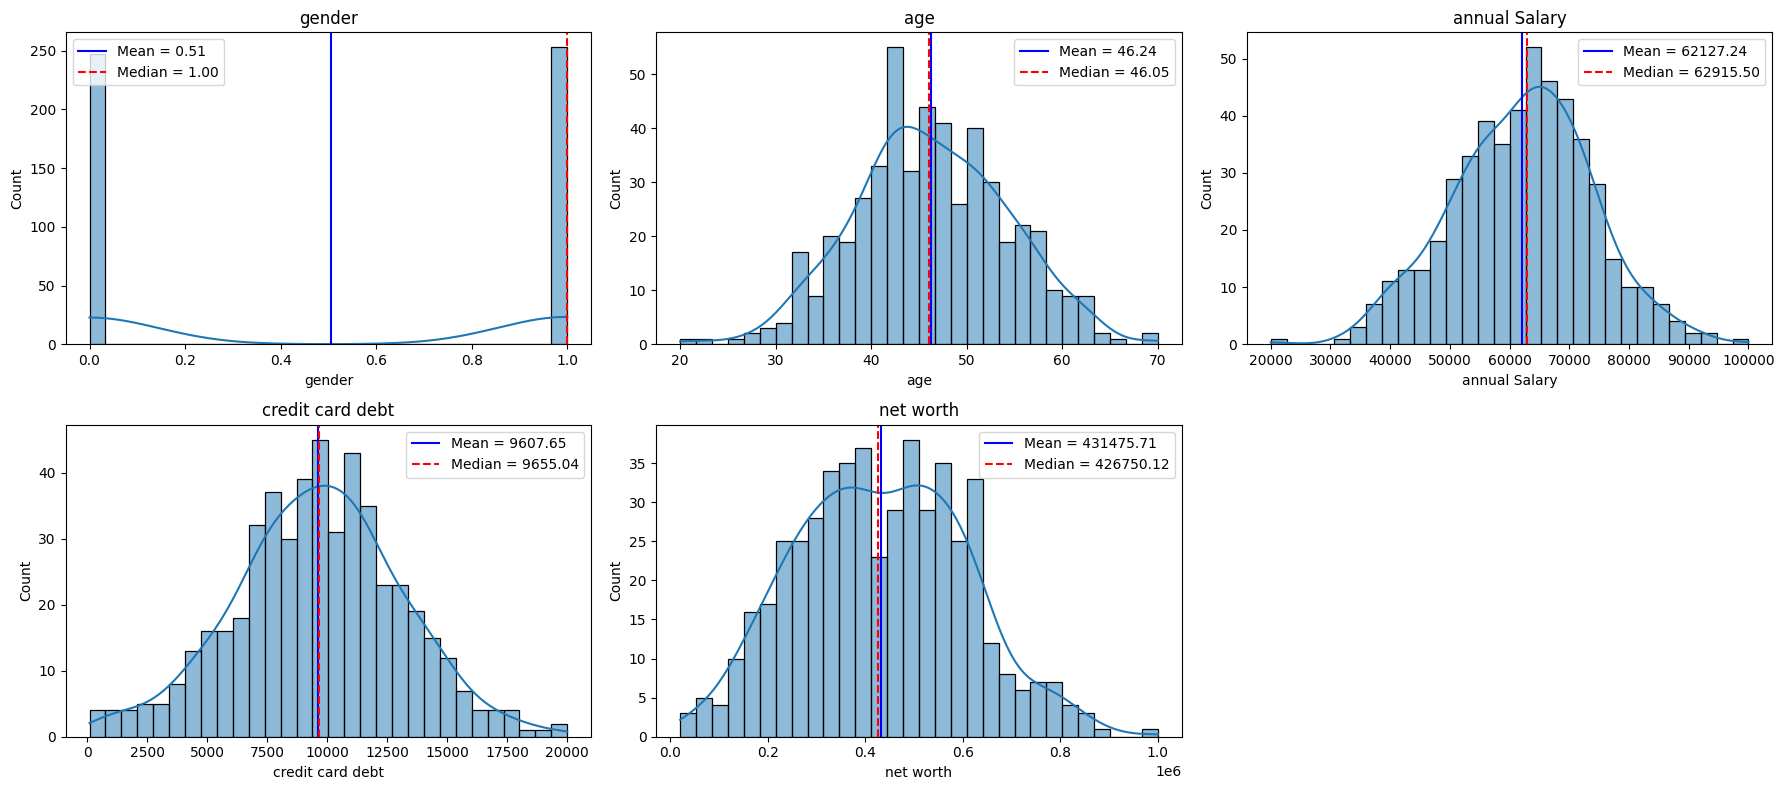

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("../data/car_purchasing.csv", encoding="latin1")


df = df.drop(["customer name", "customer e-mail", "country"], axis=1)


features = df.drop("car purchase amount", axis=1).columns


n_cols = 3
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(features):


    if df[col].dtype == "object":
        sns.countplot(data=df, x=col, ax=axes[i])


    else:
        sns.histplot(data=df, x=col, kde=True, bins=30, ax=axes[i])

        mean_val = df[col].mean()
        median_val = df[col].median()

        axes[i].axvline(mean_val, color="blue",
                        linestyle="-",
                        label=f"Mean = {mean_val:.2f}")

        axes[i].axvline(median_val, color="red",
                        linestyle="--",
                        label=f"Median = {median_val:.2f}")

        axes[i].legend()

    axes[i].set_title(col)

# Remove empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Feature scaling

In [11]:
from sklearn.preprocessing import StandardScaler
st = StandardScaler()
cols=['age','annual Salary','credit card debt','net worth'   
]
X_train[cols] = st.fit_transform(X_train[cols])
X_test[cols] = st.transform(X_test[cols])

In [12]:
from sklearn.linear_model import LinearRegression

my_LinearRegression = Linear_Regression()
lr = LinearRegression()

## Model training

In [13]:
my_LinearRegression.fit(X_train, y_train)
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [14]:
my_pred = my_LinearRegression.predict(X_test)
ski_pred = lr.predict(X_test)

## Evaluation

In [15]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

print("="*50)
print("My Linear Regression")
print("="*50)
print("MSE  :", mean_squared_error(y_test, my_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, my_pred)))
print("MAE  :", mean_absolute_error(y_test, my_pred))
print("R2   :", r2_score(y_test, my_pred))

print("\n"+"="*50)
print("Sklearn Linear Regression")
print("="*50)
print("MSE  :", mean_squared_error(y_test, ski_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, ski_pred)))
print("MAE  :", mean_absolute_error(y_test, ski_pred))
print("R2   :", r2_score(y_test, ski_pred))

My Linear Regression
MSE  : 2.2672160027555197
RMSE : 1.5057277319474194
MAE  : 1.221596830268136
R2   : 0.9999999790020407

Sklearn Linear Regression
MSE  : 2.0943696029402536
RMSE : 1.4471936991779137
MAE  : 1.153570894021068
R2   : 0.9999999806028682


## Results & conclusion

| Model | RMSE | R² |
|---|---|---|
| From scratch (gradient descent) | 1.51 | 0.99999998 |
| scikit-learn `LinearRegression` | 1.45 | 0.99999998 |

* The gradient-descent implementation converges to the same solution as scikit-learn's closed-form solver.
* Features were standardized first – gradient descent is sensitive to feature scale (salary and net worth are in the tens of thousands, age is < 100).
* The near-perfect R² comes from the dataset: car purchase amount is almost a linear combination of the features.